### importing library

In [41]:
import numpy
import pandas 
import matplotlib.pyplot
from abc import abstractmethod, ABC
from sklearn.datasets import make_blobs


### Importing Dataset

In [42]:
X, y = make_blobs(
    n_samples=100,
    centers=[(-3, -3), (3, 3)],
    cluster_std=2.0
    )

X1 = (X[:, 0] - numpy.min(X[:, 0])) / (numpy.max(X[:, 0]) - numpy.min(X[:, 0]))
X2 = (X[:, 1] - numpy.min(X[:, 1])) / (numpy.max(X[:, 1]) - numpy.min(X[:, 1]))

X1 = X1.T.reshape(100, 1)
X2 = X2.T.reshape(100, 1)

ones = numpy.ones((100, 1))
X = numpy.hstack((ones, X1, X2))

y[y==0] = -1
y = y.reshape(100, 1)

### The Perceptron algorithm

In [43]:
class Algorithm(ABC):
    def __init__(self, name):
        self.name = None
    @abstractmethod
    def fit(self):
        pass
    @abstractmethod
    def train(sellf):
        pass

class Perceptron(Algorithm):
    
    def __init__(self):
        self.weight = numpy.array(self.set_weight(), dtype=float)
        self.weight_history = [self.weight.copy()]
        self.memorization_accuracy = float

    def set_weight(self):
        w0 = numpy.random.rand()
        w1 = numpy.random.rand()
        w2 = numpy.random.rand()
        return w0, w1, w2

    def fit(self, d1, d2):    
        self.train(d1, d2)

    def train(self, data, label):
        df = numpy.hstack((data, label))
        for item in range(10):
            for instance in df:
                if numpy.dot(self.weight, instance[:3]) * instance[-1] <= 0:
                    self.weight += instance[:3] * instance[-1]
                    self.weight_history.append(self.weight.copy())
                    
        self.memorization_accuracy = self.train_acc(data, label)

    def train_acc(self, data, label):
        faults = float()
        df = numpy.hstack((data, label))
        for item in df:
            if numpy.dot(self.weight, item[:3]) * item[-1] <= 0:
                faults += 1

        return f'memorization acc : {((df.shape[0] - faults) / df.shape[0]) * 100}'

    def test_acc(self, test_set):
            faults = float()
            for item in test_set:
                if numpy.dot(self.weight, item[:3]) * item[-1] <= 0:
                    faults += 1
    
            return f'Test acc : {((test_set.shape[0] - faults) / test_set.shape[0]) * 100}'

### Object creation

In [44]:
clsfr = Perceptron()
clsfr.fit(X, y)
print(clsfr.weight)
print(clsfr.memorization_accuracy)

[-1.80028477  1.6471456   2.02080093]
memorization acc : 100.0


### Visualizing the dataset and the classifire

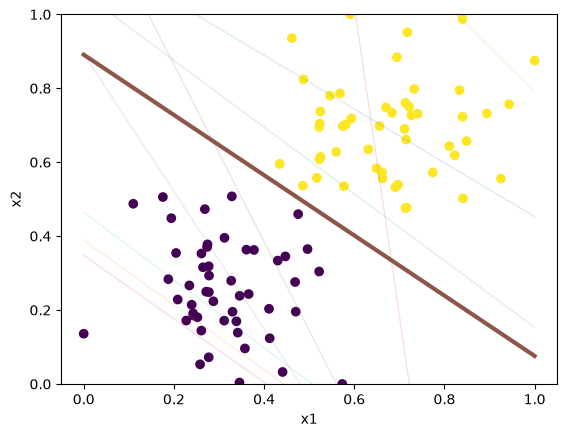

In [45]:
fig, ax = matplotlib.pyplot.subplots()

# dataset
ax.scatter(X[:, 1], X[:, 2], c=y)
ax.set_ylim(0, 1)
x1 = numpy.linspace(X[:, 1].min(), X[:, 1].max(), 200)

for weight in clsfr.weight_history:
    w0, w1, w2 = weight
    if w2 != 0:
        x2 = (-w0 - w1 * x1) / w2
        ax.plot(x1, x2, alpha=0.15, linewidth=1)

w0, w1, w2 = clsfr.weight_history[-1]
x2 = (-w0 - w1 * x1) / w2
ax.plot(
    x1,
    x2,
    alpha=1,
    linewidth=3
)
ax.set_xlabel("x1")
ax.set_ylabel("x2")
matplotlib.pyplot.show()

### Test Set

In [46]:
X_test, y_test = make_blobs(
    n_samples=100,
    centers=[(-3, -3), (3, 3)],
    cluster_std=2.0
    )

test_df0 = (X_test[:, 0] - numpy.min(X_test[:, 0])) / (numpy.max(X_test[:, 0]) - numpy.min(X_test[:, 0]))
test_df1 = (X_test[:, 1] - numpy.min(X_test[:, 1])) / (numpy.max(X_test[:, 1]) - numpy.min(X_test[:, 1]))
y_test[y_test==0] = -1

test_df = numpy.hstack((ones.reshape(100, 1), test_df0.reshape(100, 1), test_df1.reshape(100, 1), y_test.reshape(100, 1)))

In [47]:
clsfr.test_acc(test_df)

'Test acc : 100.0'

### Visualizing the Test set and the classifire learned

Text(0.5, 1.0, 'classifying test data')

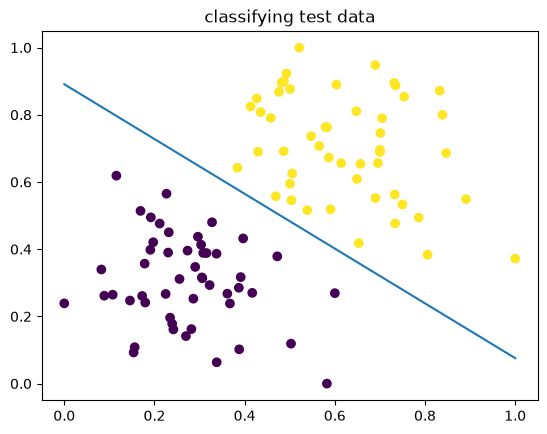

In [48]:
fig2, ax2 = matplotlib.pyplot.subplots()
ax2.scatter(test_df[:, 1], test_df[:, 2], c=test_df[:, 3])

x11 = numpy.linspace(start=0, stop=1, num=200)
x22 = (-clsfr.weight[0] - clsfr.weight[1]*x1)/clsfr.weight[2]
ax2.plot(x11, x22)
ax2.set_title('classifying test data')
